# OpenAPI와 TS SDK

**이 노트북에서 할 일**

1. 앱 객체가 만든 응답 문서에서 요청 주소와 입력 형식·응답 형식을 찾습니다.
2. 응답 문서로 만든 TS 코드(생성 SDK)에서 요청 주소마다 만든 함수를 읽습니다.
3. 인증을 적는 자리 하나만 바꾸면 응답 문서가 어떻게 바뀌는지 실험합니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
실습 앱의 에이전트 그래프도 이 절에서는 부르지 않습니다.
그래서 다시 실행해도 같은 값이 나와야 합니다.

요청은 시험용 클라이언트로 같은 노트북 안에서 보냅니다.
서버 프로그램을 띄우지 않고, 네트워크와 포트를 쓰지 않습니다.
실습 폴더의 파일을 가져오고 읽기만 하며, 쓰는 파일은 없습니다.
TS 코드를 만드는 생성기와 TS 검사 도구는 노트북에서 실행하지 않습니다.

걸린 시간은 재지 않았습니다.
앞 절에서 배운 함수는 이 절에서 쓰지 않아, 도구 파일도 가져오지 않습니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
패키지 langgraph 1.2.11과 langchain 1.4.0은 실습 앱 파일이 가져오는 패키지입니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽고, 5절 실험의 가설을 함께 세웁니다.
5절의 두 실행은 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 실습 앱 객체 app 처리 함수 다섯에서, 회색 상자 FastAPI가 처리 함수와 양식 클래스를 훑어 적음을 지나 노란 상자 응답 문서 딕셔너리 OpenAPI 3.1.0 요청 주소 다섯으로 갑니다. 이어서 노란 상자 실습 폴더 openapi.json 새로 만든 글과 같음 True, 회색 상자 생성기 7.25.0 typescript-fetch 노트북 밖 README 명령을 지나 초록 상자 생성 SDK client/generated 요청 주소마다 함수 하나에 닿는 그림](attachment:08-1-앱-객체에서-생성-SDK까지.png)

위에서 아래로 읽습니다.
초록 상자는 실습 폴더의 앱과 파일이고, 노란 상자 둘은 노트북 2절과 3절의 출력입니다.
회색 상자 둘은 라이브러리와 생성기가 하는 일이고, 생성기는 이 노트북에서 실행하지 않았습니다.
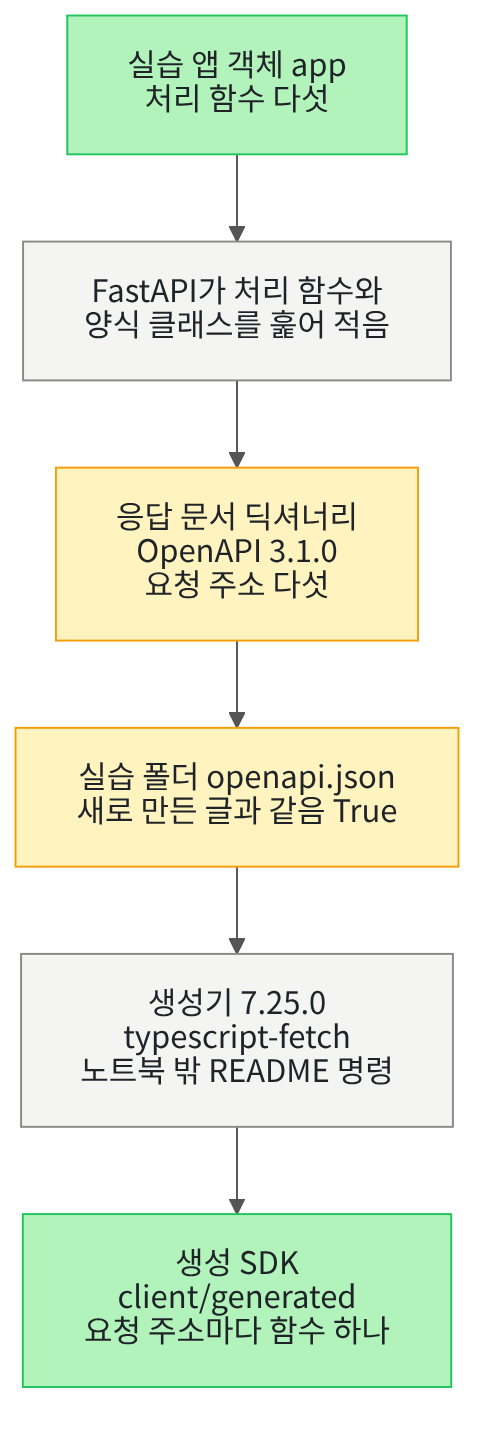

## 1. 준비

07절에서는 보안 도구 클래스 `HTTPBearer`를 쓴 새 앱의 응답 문서에만 보안 방식 칸이 있는 것을 봤습니다.
이 절은 앱 객체가 만드는 응답 문서를 처음부터 읽습니다.
제목의 OpenAPI는 요청 주소와 입력 형식·응답 형식을 JSON으로 적는 규격의 이름입니다.
제목의 TS는 TypeScript의 줄임말로, JavaScript에 자료의 형식을 적을 수 있게 한 언어입니다.
제목의 SDK는 Software Development Kit의 줄임말로, 서비스를 부르는 코드를 묶어 둔 것입니다.

이 절에서는 OpenAPI 규격으로 적은 문서를 응답 문서, 그 문서로 만든 TS 코드 묶음을 생성 SDK라고 부릅니다.
두 말은 2절과 4절에서 자세히 풉니다.
첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.
fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0
langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`과 `starlette: 1.6.0`이 보입니다.
여섯 모두 실습 폴더 잠금과 같은 판이고, 07절과 같은 목록입니다.
응답 문서를 만드는 코드는 패키지 fastapi에 들어 있습니다.
이 절은 모델 객체를 만들지 않아, API 키를 확인하는 셀도 없습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 json은 딕셔너리를 JSON 글로 바꾸고, 파일의 JSON 글을 읽을 때 씁니다.
클래스 `HTTPBearer`는 07절에서 본 보안 도구 클래스로, 5절 실험에서 씁니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os와 json은 Python에 들어 있는 모듈입니다)
import os
import json
from fastapi import Depends, FastAPI
from fastapi.security import HTTPBearer
from fastapi.testclient import TestClient

print("가져온 이름:", "json, Depends, FastAPI, HTTPBearer, TestClient")

가져온 이름: json, Depends, FastAPI, HTTPBearer, TestClient


**결과 읽기** — 출력 줄 `가져온 이름: json, Depends, FastAPI, HTTPBearer, TestClient`가 보입니다.
이 절은 앞 절에서 배운 함수를 쓰지 않아, 도구 파일 `serve_tools.py`를 가져오지 않습니다.

다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.

다음 셀은 작업 폴더를 실습 폴더로 옮긴 뒤 이름을 가져옵니다.
앱 파일에서 앱 객체 `app`과 처리 함수 `health`, 제공 함수 `require_token`을 가져옵니다.
양식 클래스 `ChatRequest`는 01절에서 본 입력 형식의 클래스입니다.
앱 객체의 속성 `openapi_schema`도 함께 출력합니다.

In [4]:
# 작업 폴더를 실습 폴더로 옮기고, 앱 객체·처리 함수·제공 함수·양식 클래스를 가져옵니다
os.chdir(lab_path)
from agent_service.app import app, health, require_token
from agent_service.schemas import ChatRequest
print("가져온 앱 객체의 종류:", type(app).__name__)
print("가져온 함수:", health.__name__, require_token.__name__)
print("응답 문서를 담아 둘 속성 openapi_schema:", app.openapi_schema)

가져온 앱 객체의 종류: FastAPI
가져온 함수: health require_token
응답 문서를 담아 둘 속성 openapi_schema: None


**결과 읽기** — 출력 줄 `가져온 앱 객체의 종류: FastAPI`와 `가져온 함수: health require_token`이 보입니다.
속성 `openapi_schema`는 아직 `None`입니다.
앱 객체는 응답 문서를 처음 부탁받을 때 만들어, 이 속성에 담아 둡니다.
그런지는 2절에서 확인합니다.

## 2. 앱 객체가 만드는 응답 문서

응답 문서(OpenAPI 문서)는 앱 객체가 요청 주소마다 받는 요청과 내놓는 응답의 모양을 적은 JSON 문서입니다.
만들 열차를 작게 줄인 모형이, 칸의 차례와 칸마다 실을 짐의 모양을 보여 주는 것과 같습니다.
이 앱에서는 앱 객체의 메서드 `openapi`가 이 문서를 딕셔너리로 내놓습니다.
문서의 모양은 OpenAPI 규격이 정하고, 맨 위 칸 `openapi`에 그 규격의 판이 적힙니다.

다음 셀은 메서드 `openapi`를 불러 응답 문서를 만들고, 맨 위 칸을 봅니다.

In [5]:
# 앱 객체의 메서드 openapi를 불러 응답 문서를 만들고, 맨 위 칸을 봅니다
openapi_doc = app.openapi()
print("받은 값의 종류:", type(openapi_doc).__name__)
print("맨 위 칸:", list(openapi_doc))
print("OpenAPI 판:", openapi_doc["openapi"])
print("칸 info:", openapi_doc["info"])

받은 값의 종류: dict
맨 위 칸: ['openapi', 'info', 'paths', 'components']
OpenAPI 판: 3.1.0
칸 info: {'title': '교육용 Agent API', 'version': '1.0.0'}


**결과 읽기** — 출력 줄 `OpenAPI 판: 3.1.0`이 보입니다.
맨 위 칸은 넷이고, 칸 `info`에는 앱 파일 17행에 적은 제목과 판 `1.0.0`이 들어 있습니다.
판 `1.0.0`은 이 앱에 붙인 판이고, 패키지 fastapi의 판과는 다른 값입니다.
칸 `paths`는 요청 주소마다 받는 요청과 응답을 적고, 칸 `components`는 여러 곳에서 쓰는 형식을 모아 둡니다.

다음 셀은 칸 `paths`에 적힌 요청 주소와 요청 방식을 한 줄씩 출력합니다.

In [6]:
# 칸 paths에 적힌 요청 주소와, 요청 주소마다 받는 요청 방식을 한 줄씩 출력합니다
print("요청 주소 수:", len(openapi_doc["paths"]))
print("요청 주소 | 요청 방식")
for address in openapi_doc["paths"]:
    print(address, "|", list(openapi_doc["paths"][address]))

요청 주소 수: 5
요청 주소 | 요청 방식
/health | ['get']
/v1/chat | ['post']
/v1/chat/live | ['post']
/v1/chat/stream | ['post']
/v1/chat/live/stream | ['post']


**결과 읽기** — 출력 줄 `요청 주소 수: 5`와, 라벨 줄 아래 다섯 줄이 보입니다.
앱 파일에서 요청 주소 데코레이터 줄로 이은 처리 함수 다섯이 모두 적혔습니다.
요청 주소 `/openapi.json`은 이 목록에 없습니다.
설치판 fastapi `applications.py` 1117행이 문서를 내주는 요청 주소를 문서에서 빼기 때문입니다.

다음 셀은 01절부터 써 온 요청 주소 `/v1/chat`의 칸을 꺼냅니다.
요청 본문과 응답의 형식이 어떻게 적혔는지 봅니다.

In [7]:
# 요청 주소 /v1/chat의 POST 칸에서, 이름표와 요청 본문·응답의 형식이 적힌 자리를 꺼냅니다
chat_operation = openapi_doc["paths"]["/v1/chat"]["post"]
print("POST /v1/chat의 칸:", list(chat_operation))
print("operationId:", chat_operation["operationId"])
print("요청 본문 형식:", chat_operation["requestBody"]["content"]["application/json"]["schema"])
print("응답 코드:", list(chat_operation["responses"]))
print("200 응답 형식:", chat_operation["responses"]["200"]["content"]["application/json"]["schema"])
print("매개변수 이름과 자리:", chat_operation["parameters"][0]["name"], chat_operation["parameters"][0]["in"])

POST /v1/chat의 칸: ['summary', 'operationId', 'parameters', 'requestBody', 'responses']
operationId: chat_v1_chat_post
요청 본문 형식: {'$ref': '#/components/schemas/ChatRequest'}
응답 코드: ['200', '422']
200 응답 형식: {'$ref': '#/components/schemas/ChatResponse'}
매개변수 이름과 자리: authorization header


**결과 읽기** — 출력 줄 `응답 코드: ['200', '422']`와 `operationId: chat_v1_chat_post`가 보입니다.
요청 본문 형식과 200 응답 형식에는 형식 대신 키 `$ref` 하나가 있습니다.
키 `$ref`는 같은 문서의 다른 자리를 가리키는 표시입니다.
값 `#/components/schemas/ChatRequest`는 맨 위 칸 `components`에서 `schemas`, `ChatRequest` 차례로 들어간 자리입니다.
응답 코드 422는 01절에서 본 입력 형식 검사의 응답입니다.

칸 `operationId`는 요청 주소마다 붙는 이름입니다.
설치판 fastapi `utils.py` 95~100행이 처리 함수 이름과 요청 주소, 요청 방식을 이어 만듭니다.
매개변수 `authorization`은 07절에서 본 것처럼, 요청 머리에서 읽는 값입니다.

다음 셀은 칸 `components`에 모은 형식 이름과, 입력 형식 `ChatRequest`의 칸 조건을 봅니다.
마지막 줄은 Ch 19 02절에서 쓴 메서드 `model_json_schema`로 만든 딕셔너리와 견줍니다.

In [8]:
# 칸 components에 모은 형식 이름과, 입력 형식 ChatRequest에 적힌 칸 조건을 봅니다
format_table = openapi_doc["components"]["schemas"]
print("형식 이름:", list(format_table))
print("ChatRequest의 꼭 채울 칸:", format_table["ChatRequest"]["required"])
print("칸 question:", format_table["ChatRequest"]["properties"]["question"])
print("칸 thread_id의 pattern:", format_table["ChatRequest"]["properties"]["thread_id"]["pattern"])
print("model_json_schema()로 만든 딕셔너리와 같은가:", ChatRequest.model_json_schema() == format_table["ChatRequest"])

형식 이름: ['ChatRequest', 'ChatResponse', 'HTTPValidationError', 'HealthResponse', 'ValidationError']
ChatRequest의 꼭 채울 칸: ['question', 'thread_id']
칸 question: {'type': 'string', 'maxLength': 500, 'minLength': 1, 'title': 'Question', 'examples': ['휴관일을 알려 주세요']}
칸 thread_id의 pattern: ^[a-zA-Z0-9_-]{1,64}$
model_json_schema()로 만든 딕셔너리와 같은가: True


**결과 읽기** — 출력 줄 `칸 question:`에 `'maxLength': 500`과 `'minLength': 1`이 보입니다.
실습 파일 `schemas.py`의 양식 클래스에 `Field`로 적은 글자 수 조건이 그대로 적혔습니다.
꼭 채울 칸은 `question`과 `thread_id` 둘이고, 칸 `thread_id`에는 글 모양 조건 `pattern`이 있습니다.
마지막 줄은 `True`로, Ch 19 02절 방법으로 만든 딕셔너리와 같았습니다.

형식 이름 다섯 가운데 `HTTPValidationError`와 `ValidationError`는 422 응답을 적으려고 라이브러리가 더한 형식입니다.
앱 파일에는 이 두 이름의 클래스가 없습니다.

다음 셀은 JSON 글로 답하는 `/v1/chat`과, SSE 사건으로 답하는 `/v1/chat/stream`의 200 응답을 견줍니다.
본문 종류와, 그 아래에 적힌 키를 봅니다.

In [9]:
# 요청 주소 /v1/chat과 /v1/chat/stream의 200 응답에서, 본문 종류와 그 아래 키를 견줍니다
chat_content = chat_operation["responses"]["200"]["content"]
stream_operation = openapi_doc["paths"]["/v1/chat/stream"]["post"]
stream_content = stream_operation["responses"]["200"]["content"]
print("/v1/chat:", list(chat_content), list(chat_content["application/json"]))
print("/v1/chat/stream:", list(stream_content), list(stream_content["text/event-stream"]))

/v1/chat: ['application/json'] ['schema']
/v1/chat/stream: ['text/event-stream'] ['itemSchema']


**결과 읽기** — 출력 줄 `/v1/chat/stream: ['text/event-stream'] ['itemSchema']`가 보입니다.
요청 주소 `/v1/chat`은 본문 종류 `application/json` 아래에 키 `schema`로 응답 형식을 적었습니다.
SSE 사건으로 답하는 요청 주소는 키 `itemSchema`로, SSE 사건 하나의 형식을 적었습니다.
05절의 작은 앱에서 본 것처럼, 이 키 아래에 칸 `data`·`event`·`id`·`retry`가 적힙니다.
이 차이가 4절의 생성 SDK에서 다시 나옵니다.

다음 셀은 메서드 `openapi`를 한 번 더 불러, 처음 받은 딕셔너리와 같은 객체인지 봅니다.

In [10]:
# 메서드 openapi를 한 번 더 불러, 처음 받은 딕셔너리와 같은 객체인지 봅니다
second_doc = app.openapi()
print("두 번째로 받은 값이 같은 객체인가:", second_doc is openapi_doc)
print("속성 openapi_schema가 같은 객체인가:", app.openapi_schema is openapi_doc)

두 번째로 받은 값이 같은 객체인가: True
속성 openapi_schema가 같은 객체인가: True


**결과 읽기** — 두 줄 모두 `True`입니다.
연산자 `is`는 두 이름이 같은 객체를 가리키는지 봅니다.
앱 객체는 처음 만든 문서를 속성 `openapi_schema`에 담아 두고, 다음부터는 그 객체를 그대로 내놓습니다.
설치판 fastapi `applications.py` 1083~1084행이 문서가 없을 때만 새로 만듭니다.

그래서 문서를 만든 뒤에 이은 요청 주소는 문서에 나오지 않습니다.
이 노트북에서는 실행하지 않았고, 노트북 밖에서 한 번 확인했습니다.

다음 셀은 요청 주소 `/openapi.json`으로 같은 문서를 받아 봅니다.
시험용 클라이언트로 GET을 보냅니다.

In [11]:
# 시험용 클라이언트로 요청 주소 /openapi.json에 GET을 보내, 받은 문서가 같은지 봅니다
client = TestClient(app)
doc_response = client.get("/openapi.json")
print("상태 코드:", doc_response.status_code)
print("본문 종류:", doc_response.headers["content-type"])
print("메서드 openapi가 내놓은 딕셔너리와 같은가:", doc_response.json() == openapi_doc)

상태 코드: 200
본문 종류: application/json
메서드 openapi가 내놓은 딕셔너리와 같은가: True


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `본문 종류: application/json`이 보입니다.
받은 문서를 읽은 딕셔너리는 메서드 `openapi`가 내놓은 딕셔너리와 같았습니다.
실습 폴더 README는 서버를 띄운 뒤 주소 `/docs`와 `/openapi.json`에서 이 문서를 보라고 적습니다.
이 절에서는 서버를 띄우지 않아, 그 화면은 열지 않았습니다.

## 3. 응답 문서와 openapi.json

실습 폴더 맨 위에는 파일 `openapi.json`이 있습니다.
응답 문서를 JSON 글로 적은 파일이고, 4절의 생성 SDK는 이 문서를 생성기에 넣어 만든 코드입니다.
다음 셀은 응답 문서를 이 파일과 같은 설정의 JSON 글로 바꿔, 파일 글과 견줍니다.
인자 `ensure_ascii=False`는 한글을 그대로 적게 하고, 인자 `indent`는 칸마다 줄을 바꿔 들여 쓰게 합니다.
파일은 읽기만 하고 다시 쓰지 않습니다.

In [12]:
# 응답 문서를 openapi.json과 같은 설정의 JSON 글로 바꾸고, 파일 글과 견줍니다(파일은 읽기만 합니다)
openapi_text = json.dumps(openapi_doc, ensure_ascii=False, indent=2)
with open("openapi.json", encoding="utf-8") as doc_file:
    file_text = doc_file.read()
print("새로 만든 글의 글자 수:", len(openapi_text))
print("파일 글의 글자 수:", len(file_text))
print("두 글이 같은가:", openapi_text == file_text)
print("ensure_ascii를 뺀 글과 같은가:", json.dumps(openapi_doc, indent=2) == file_text)
print("파일 첫 세 줄:", file_text.splitlines()[:3])

새로 만든 글의 글자 수: 9987
파일 글의 글자 수: 9987
두 글이 같은가: True
ensure_ascii를 뺀 글과 같은가: False
파일 첫 세 줄: ['{', '  "openapi": "3.1.0",', '  "info": {']


**결과 읽기** — 출력 줄 `두 글이 같은가: True`가 보입니다.
두 글의 글자 수도 `9987`로 같습니다.
인자 `ensure_ascii`를 뺀 글은 한글이 유니코드 번호로 적혀, 파일 글과 같지 않았습니다.
파일 첫 줄은 중괄호이고, 둘째 줄에 규격의 판이 적혀 있습니다.

지금 앱으로 만든 글과 파일 글이 같으므로, 이 노트북은 파일을 다시 쓰지 않습니다.
파일로 쓸 때는 이 글을 `with open(…, "w", encoding="utf-8")`로 연 파일에 적습니다.
앱 파일의 요청 주소나 양식 클래스를 바꾸면 이 글이 달라집니다.
그때는 파일과 생성 SDK를 함께 다시 만듭니다.

## 4. 생성 SDK 읽기

생성 SDK는 응답 문서를 생성기에 넣어 만든, 앱을 부르는 코드 묶음입니다.
차량 공장이 축소 모형만 보고 실제 화물 칸을 만드는 것과 같습니다.
이 실습 폴더에서는 `client/generated/` 폴더의 파일 열여덟(TS 파일 열하나와 설명 문서 일곱)이 생성 SDK입니다.
생성기는 OpenAPI Generator의 `typescript-fetch`로, 06절에서 본 함수 `fetch`로 요청을 보내는 코드를 만듭니다.
생성기는 Java 프로그램이라서, README 명령으로 노트북 밖에서 실행합니다.

다음 셀은 이 절에서 쓸 함수를 정의합니다.
글 줄 목록에서 낱말이 든 줄을 찾아, 줄 번호와 함께 출력합니다.

In [13]:
# 글 줄 목록에서 word가 든 줄을 찾아, 줄 번호와 앞뒤 공백을 뺀 줄을 한 줄씩 출력합니다
def print_lines_with(text_lines, word):
    print("줄 번호 | 줄")
    for index in range(len(text_lines)):
        if word in text_lines[index]:
            print(index + 1, "|", text_lines[index].strip())

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `strip`은 줄 앞뒤의 공백을 뺀 글을 내놓습니다.
줄 번호는 0부터 세는 자리에 1을 더해, 파일을 열었을 때의 줄 번호와 맞춥니다.

다음 셀은 파일 `openapitools.json`에서 생성기 판을 읽습니다.
그다음 생성 SDK 파일 `DefaultApi.ts`의 머리 주석에서 줄 셋을 찾습니다.
함수 `json.load`는 연 파일의 JSON 글을 읽어 파이썬 값으로 바꿉니다.

In [14]:
# openapitools.json에서 생성기 판을 읽고, 생성 SDK 파일 DefaultApi.ts의 머리 주석에서 줄 셋을 찾습니다
with open("openapitools.json", encoding="utf-8") as tools_file:
    generator_config = json.load(tools_file)
print("생성기 판:", generator_config["generator-cli"]["version"])
with open("client/generated/apis/DefaultApi.ts", encoding="utf-8") as ts_file:
    ts_lines = ts_file.read().splitlines()
print_lines_with(ts_lines, "The version of the OpenAPI document")
print_lines_with(ts_lines, "auto generated")
print_lines_with(ts_lines, "Do not edit")

생성기 판: 7.25.0
줄 번호 | 줄
7 | * The version of the OpenAPI document: 1.0.0
줄 번호 | 줄
10 | * NOTE: This class is auto generated by OpenAPI Generator (https://openapi-generator.tech).
줄 번호 | 줄
12 | * Do not edit the class manually.


**결과 읽기** — 출력 줄 `생성기 판: 7.25.0`이 보입니다.
7행에는 응답 문서의 칸 `info`에 있던 판 `1.0.0`이 적혔습니다.
10행과 12행은 이 파일을 생성기가 만들었으니, 손으로 고치지 말라는 주석입니다.
고칠 일이 있으면 앱 파일을 고치고, 응답 문서와 생성 SDK를 다시 만듭니다.

다음 셀은 같은 파일에서 요청 주소마다 만든 함수를 찾습니다.
네 칸 들여 쓴 `async`로 시작하고, 이름에 `Raw(`와 `RequestOpts(`가 없는 줄이 앱을 부를 때 쓰는 함수입니다.
메서드 `rstrip`은 줄 끝의 공백과 `{`를 빼고, 메서드 `split`은 주어진 글에서 나눕니다.

In [15]:
# DefaultApi.ts에서 요청 주소마다 만든 함수의 이름과, 내놓는 값의 형식을 찾습니다
print("줄 번호 | 함수 이름 | 내놓는 값")
for index in range(len(ts_lines)):
    line = ts_lines[index]
    if line.startswith("    async ") and "Raw(" not in line and "RequestOpts(" not in line:
        signature = line.strip().rstrip(" {")
        name = signature.split("(")[0]
        returned = signature.split("): ")[-1]
        print(index + 1, "|", name, "|", returned)

줄 번호 | 함수 이름 | 내놓는 값
140 | async chatStreamV1ChatStreamPost | Promise<void>
190 | async chatV1ChatPost | Promise<ChatResponse>
227 | async healthHealthGet | Promise<HealthResponse>
278 | async liveChatStreamV1ChatLiveStreamPost | Promise<void>
328 | async liveChatV1ChatLivePost | Promise<ChatResponse>


**결과 읽기** — 라벨 줄 아래 다섯 줄이, 요청 주소 다섯에 하나씩 만든 함수입니다.
JSON 글로 답하는 요청 주소 셋의 함수는 `Promise<ChatResponse>`나 `Promise<HealthResponse>`를 내놓습니다.
SSE 사건으로 답하는 요청 주소 둘의 함수는 140행과 278행에서 `Promise<void>`를 내놓습니다.
형식 `Promise`는 TS에서 await로 기다려 값을 받는 객체이고, `void`는 줄 값이 없다는 표시입니다.

함수 이름은 2절의 칸 `operationId`를 TS 이름 모양으로 바꾼 것입니다.
예를 들어 `chat_v1_chat_post`가 190행의 `chatV1ChatPost`가 되었습니다.
이름 앞의 `async`는 TS에서도 비동기 함수라는 표시입니다.

다음 셀은 이 함수들이 받은 응답을 어떻게 감싸는지 찾습니다.

In [16]:
# DefaultApi.ts에서 받은 응답을 감싸는 줄을 찾습니다 — 본문을 읽지 않는 쪽과 JSON으로 읽는 쪽
print_lines_with(ts_lines, "VoidApiResponse(response")
print_lines_with(ts_lines, "JSONApiResponse(response")

줄 번호 | 줄
134 | return new runtime.VoidApiResponse(response);
272 | return new runtime.VoidApiResponse(response);
줄 번호 | 줄
184 | return new runtime.JSONApiResponse(response, (jsonValue) => ChatResponseFromJSON(jsonValue));
221 | return new runtime.JSONApiResponse(response, (jsonValue) => HealthResponseFromJSON(jsonValue));
322 | return new runtime.JSONApiResponse(response, (jsonValue) => ChatResponseFromJSON(jsonValue));


**결과 읽기** — 첫 라벨 줄 아래 134행과 272행이 받은 응답을 `VoidApiResponse`로 감쌉니다.
둘째 라벨 줄 아래 세 줄은 `JSONApiResponse`로 감싸고, 본문 JSON을 `ChatResponse` 같은 형식으로 바꿉니다.
SSE 사건으로 답하는 요청 주소 둘의 함수는 응답 본문을 읽어 값으로 주지 않는다는 뜻입니다.
2절에서 본 것처럼, 두 요청 주소는 응답 형식을 키 `schema`가 아니라 `itemSchema`로 적었습니다.

노트북 밖에서 생성기를 실행해 보니, 생성기는 키 `itemSchema`를 뜻밖의 칸이라고 경고했습니다.
SSE 사건은 06절에서 글로 읽은 TS 파일 `client/stream.ts`가 함수 `fetch`로 읽습니다.
생성 SDK와 손으로 쓴 이 파일이 요청 주소를 나눠 맡습니다.

다음 셀은 요청 인자의 칸을 적은 TS 선언과, 그 안의 칸 `authorization`을 찾습니다.

In [17]:
# 요청 인자의 칸을 적은 TS 선언과, 그 안의 칸 authorization이 적힌 줄을 찾습니다
print_lines_with(ts_lines, "export interface")
print_lines_with(ts_lines, "authorization?:")

줄 번호 | 줄
37 | export interface ChatStreamV1ChatStreamPostRequest {
52 | export interface ChatV1ChatPostRequest {
63 | export interface LiveChatStreamV1ChatLiveStreamPostRequest {
74 | export interface LiveChatV1ChatLivePostRequest {
줄 번호 | 줄
45 | authorization?: string | null;
60 | authorization?: string | null;
71 | authorization?: string | null;
82 | authorization?: string | null;


**결과 읽기** — 첫 라벨 줄 아래 네 줄은 요청 인자의 칸을 적은 TS 선언 `interface`입니다.
둘째 라벨 줄 아래 45·60·71·82행에서, 네 선언 모두 칸 `authorization?: string | null`을 가집니다.
칸 이름 뒤의 `?`는 넣지 않아도 되는 칸이라는 표시입니다.
실습 앱이 접근 토큰을 요청 머리 매개변수로 받아서, 생성 SDK도 요청마다 인자로 받습니다.
요청 주소 `/health`는 접근 토큰을 받지 않아, 요청 인자 선언이 없습니다.

다음 셀은 생성 SDK의 `models/ChatRequest.ts`에서 줄 넷을 찾습니다.
칸 이름의 줄, JSON 칸 이름으로 옮기는 두 줄, 글자 수 조건의 줄입니다.

In [18]:
# models/ChatRequest.ts에서 칸 이름의 줄, JSON 칸 이름으로 옮기는 줄, 글자 수 조건의 줄을 찾습니다
with open("client/generated/models/ChatRequest.ts", encoding="utf-8") as model_file:
    model_lines = model_file.read().splitlines()
print_lines_with(model_lines, ": string;")
print_lines_with(model_lines, "json['thread_id']")
print_lines_with(model_lines, "value['threadId']")
print_lines_with(model_lines, "Length")

줄 번호 | 줄
25 | question: string;
29 | threadId: string;
줄 번호 | 줄
52 | 'threadId': json['thread_id'],
줄 번호 | 줄
68 | 'thread_id': value['threadId'],
줄 번호 | 줄


**결과 읽기** — 첫 라벨 줄 아래 25행과 29행이 입력 형식 `ChatRequest`의 두 칸입니다.
응답 문서의 칸 이름 `thread_id`가 TS 쪽에서는 `threadId`로 바뀌었습니다.
52행은 받은 JSON의 `thread_id`를 `threadId`로 옮기고, 68행은 보낼 때 다시 `thread_id`로 적습니다.
마지막 라벨 줄 아래에는 아무 줄도 없습니다.

생성기 문서는 칸 이름을 바꾸는 설정의 기본값이 낙타 등 모양 이름(camelCase)이라고 적습니다.
TS 형식에는 칸 이름과 글이라는 형식만 있고, 글자 수 조건은 없습니다.
그 조건은 서버의 입력 형식 검사가 맡아, 어기면 422로 답합니다.

## 5. 실험: 인증을 적는 자리 바꾸기

07절에서는 `HTTPBearer`를 쓴 새 앱의 응답 문서에만 보안 방식 칸이 있었습니다.
그런데 07절의 두 앱은 처리 함수와 요청 주소, 요청 방식도 서로 달랐습니다.
보안 방식 칸이 인증을 적는 방법 때문에 생겼는지 보려면, 다른 것은 같게 두고 그 하나만 바꿔야 합니다.
이 실험은 새 앱 객체 둘에 같은 처리 함수 `health`를 같은 요청 주소로 잇습니다.
바꿀 값은 의존성으로 적는 것 하나입니다.

인자 `dependencies`는 처리 함수의 매개변수로 받지 않을 의존성을 적는 자리입니다.
FastAPI 문서는 여기에 적은 의존성도 보통 의존성처럼 실행되고, 오류로 멈출 수 있다고 적습니다.
메서드 `add_api_route`는 05절에서 본, 처리 함수를 요청 방식과 요청 주소에 잇는 메서드입니다.

**가설** — 07절의 결과대로라면, 실행 2에만 보안 방식 칸 `securitySchemes`가 생길 것입니다.
실행 1은 실습 앱처럼, 매개변수 `authorization`이 요청 머리 자리로 적힐 것입니다.
머리 없는 요청은 두 실행 모두 401을 받을 것입니다.

**실행 1** — 다음 셀은 실습 앱의 제공 함수 `require_token`을 의존성으로 적습니다.
실행 전에 예상해 봅니다.
응답 코드 목록에 422가 있을까요?

In [19]:
# 실행 1: 실습 앱의 제공 함수 require_token을 의존성으로 적어, 처리 함수 health를 새 앱 객체에 잇습니다
header_app = FastAPI()
header_app.add_api_route("/v1/ping", health, methods=["GET"], dependencies=[Depends(require_token)])
header_doc = header_app.openapi()
header_operation = header_doc["paths"]["/v1/ping"]["get"]
print("보안 방식 칸이 있는가:", "securitySchemes" in header_doc["components"])
print("요청 주소에 적힌 칸:", list(header_operation))
print("매개변수 이름과 자리:", header_operation["parameters"][0]["name"], header_operation["parameters"][0]["in"])
print("응답 코드:", list(header_operation["responses"]))

보안 방식 칸이 있는가: False
요청 주소에 적힌 칸: ['summary', 'operationId', 'parameters', 'responses']
매개변수 이름과 자리: authorization header
응답 코드: ['200', '422']


**결과 읽기** — 출력 줄 `보안 방식 칸이 있는가: False`와 `응답 코드: ['200', '422']`가 보입니다.
제공 함수의 매개변수 `authorization`이 요청 주소의 매개변수로 적혔습니다.
매개변수가 있으니, 그 값이 맞지 않을 때의 422 응답도 함께 적혔습니다.
설치판 fastapi `openapi/utils.py` 457~470행이 매개변수나 요청 본문이 있을 때만 422를 적습니다.

**실행 2** — 다음 셀은 값 하나만 바꿔, 의존성에 보안 객체를 적습니다.
보안 객체 `bearer`는 07절처럼 `HTTPBearer()`로 만듭니다.
요청 주소와 요청 방식, 처리 함수는 실행 1과 같습니다.
실행 전에 예상해 봅니다.
요청 주소에 적힌 칸은 어떻게 바뀔까요?

In [20]:
# 실행 2: 값 하나만 바꿔, 의존성에 보안 객체를 적고 같은 처리 함수를 같은 요청 주소에 잇습니다
bearer = HTTPBearer()
bearer_app = FastAPI()
bearer_app.add_api_route("/v1/ping", health, methods=["GET"], dependencies=[Depends(bearer)])
bearer_doc = bearer_app.openapi()
bearer_operation = bearer_doc["paths"]["/v1/ping"]["get"]
print("보안 방식 칸이 있는가:", "securitySchemes" in bearer_doc["components"])
print("요청 주소에 적힌 칸:", list(bearer_operation))
print("보안 방식:", bearer_doc["components"]["securitySchemes"])
print("요청 주소의 security 칸:", bearer_operation["security"])
print("응답 코드:", list(bearer_operation["responses"]))

보안 방식 칸이 있는가: True
요청 주소에 적힌 칸: ['summary', 'operationId', 'responses', 'security']
보안 방식: {'HTTPBearer': {'type': 'http', 'scheme': 'bearer'}}
요청 주소의 security 칸: [{'HTTPBearer': []}]
응답 코드: ['200']


**결과 읽기** — 출력 줄 `보안 방식 칸이 있는가: True`와 `응답 코드: ['200']`이 보입니다.
칸 `components`에 보안 방식 `HTTPBearer`가 생겼고, 요청 주소에는 칸 `security`가 생겼습니다.
칸 `parameters`는 없어졌고, 매개변수가 없으니 422도 적히지 않았습니다.
설치판 `openapi/utils.py` 289~296행이 보안 객체를 찾아 칸 `security`를 적습니다.
같은 파일 573~575행은 찾은 보안 방식을 칸 `components`에 모읍니다.

다음 셀은 두 앱 객체에 요청을 보내, 상태 코드도 견줍니다.
머리 없는 요청과, 교재용 접근 토큰을 실은 요청입니다.

In [21]:
# 두 앱 객체에 머리 없는 요청과 교재용 접근 토큰을 실은 요청을 보내, 상태 코드를 봅니다
auth_headers = {"Authorization": "Bearer local-demo-token"}
header_client = TestClient(header_app)
bearer_client = TestClient(bearer_app)
header_plain = header_client.get("/v1/ping")
header_token = header_client.get("/v1/ping", headers=auth_headers)
bearer_plain = bearer_client.get("/v1/ping")
bearer_token = bearer_client.get("/v1/ping", headers=auth_headers)
print("실행 1:", header_plain.status_code, header_plain.json(), header_token.status_code)
print("실행 2:", bearer_plain.status_code, bearer_plain.json(), bearer_token.status_code)

실행 1: 401 {'detail': '인증 정보가 올바르지 않습니다'} 200
실행 2: 401 {'detail': 'Not authenticated'} 200


**결과 읽기** — 두 줄 모두 머리 없는 요청은 `401`, 교재용 접근 토큰을 실은 요청은 `200`입니다.
상태 코드는 같았고, 401 응답 본문의 글만 달랐습니다.
07절에서 본 것처럼 실행 2의 보안 객체는 접근 토큰 글을 견주지 않습니다.
이 셀에서는 틀린 글을 보내지 않아, 그 차이는 보지 않았습니다.

다음 셀은 두 실행을 한 표로 모읍니다.

In [22]:
# 두 실행의 의존성·응답 문서의 칸·상태 코드를 한 표로 모읍니다
print("견준 것 | 실행 1 | 실행 2")
print("의존성에 적은 것 | require_token | HTTPBearer()")
print("보안 방식 칸 |", "securitySchemes" in header_doc["components"], "|", "securitySchemes" in bearer_doc["components"])
print("security 칸 |", "security" in header_operation, "|", "security" in bearer_operation)
print("parameters 칸 |", "parameters" in header_operation, "|", "parameters" in bearer_operation)
print("응답 코드 |", list(header_operation["responses"]), "|", list(bearer_operation["responses"]))
print("머리 없는 요청 |", header_plain.status_code, "|", bearer_plain.status_code)
print("교재용 접근 토큰 |", header_token.status_code, "|", bearer_token.status_code)

견준 것 | 실행 1 | 실행 2
의존성에 적은 것 | require_token | HTTPBearer()
보안 방식 칸 | False | True
security 칸 | False | True
parameters 칸 | True | False
응답 코드 | ['200', '422'] | ['200']
머리 없는 요청 | 401 | 401
교재용 접근 토큰 | 200 | 200


**결과 읽기** — 라벨 줄 아래 일곱 줄이 두 실행을 견줍니다.
줄 `보안 방식 칸 | False | True`와 `security 칸 | False | True`가 보입니다.
줄 `parameters 칸 | True | False`에서, 매개변수 칸은 실행 1에만 있습니다.
상태 코드 두 줄은 `머리 없는 요청 | 401 | 401`과 `교재용 접근 토큰 | 200 | 200`으로 같습니다.

**결론** — 바꾼 값은 인자 `dependencies`에 적은 것 하나였습니다.
두 요청의 상태 코드는 같았지만, 응답 문서는 달랐습니다.
보안 객체를 적은 실행 2에만 보안 방식 칸과 칸 `security`가 생겼습니다.
실습 앱은 실행 1 모양이라, 4절의 생성 SDK도 접근 토큰을 요청마다 인자로 받았습니다.
이 노트북은 걸린 시간을 재지 않았고, 응답 문서의 칸과 상태 코드만 확인했습니다.

## 정리

1. 메서드 `openapi`가 내놓은 응답 문서는 실습 폴더 `openapi.json`과 글이 같았습니다.
2. 생성 SDK에서 SSE 사건으로 답하는 요청 주소 둘의 함수는 `Promise<void>`를 내놓았습니다.
3. 의존성 하나만 보안 객체로 바꾸자, 상태 코드는 같은데 응답 문서에 보안 방식 칸이 생겼습니다.

09절에서는 실제로 모델을 부르는 에이전트를 요청 주소 `/v1/chat/live`로 부릅니다.